In [3]:
# Q1(a)
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [4]:
data = fetch_olivetti_faces()

x = data.data
y = data.target

print(x.shape)
print(y.shape)
print(data.images.shape)

(400, 4096)
(400,)
(400, 64, 64)


In [5]:
seed = 26011

r1 = np.random.default_rng(seed)

train_id = []
val_id = []
test_id = []

for i in range(40):
    id = np.where(y == i)[0]
    r1.shuffle(id)

    train_id.extend(id[:6])
    val_id.extend(id[6:8])
    test_id.extend(id[8:10])

train_id = np.array(train_id)
val_id = np.array(val_id)
test_id = np.array(test_id)

np.savez("olivetti_split.npz",
         train_id=train_id,
         val_id=val_id,
         test_id=test_id)

print(len(train_id))
print(len(val_id))
print(len(test_id))

240
80
80


In [6]:
x_train = x[train_id]
y_train = y[train_id]

x_val = x[val_id]
y_val = y[val_id]

x_test = x[test_id]
y_test = y[test_id]

In [7]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

results = []

best_accuracy = 0
best_depth = None
best_leaf = None

for depth in depth_values:
    for leaf in leaf_values:

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=seed
        )

        model.fit(x_train, y_train)

        train_pred = model.predict(x_train)
        val_pred = model.predict(x_val)

        train_accuracy = accuracy_score(y_train, train_pred)
        val_accuracy = accuracy_score(y_val, val_pred)

        results.append([
            depth, leaf, train_accuracy, val_accuracy
        ])

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_depth = depth
            best_leaf = leaf

results = pd.DataFrame(
    results,
    columns=[
        "max_depth",
        "min_samples_leaf",
        "Train Accuracy",
        "Validation Accuracy"
    ]
)

results

,max_depth,min_samples_leaf,Train Accuracy,Validation Accuracy
0,2.0,1,0.075,0.0750
1,2.0,2,0.075,0.0750
2,2.0,4,0.075,0.0750
3,4.0,1,0.125,0.1000
4,4.0,2,0.125,0.1000
5,4.0,4,0.125,0.1000
6,8.0,1,0.225,0.1625
7,8.0,2,0.225,0.1625
8,8.0,4,0.225,0.1625
9,16.0,1,0.425,0.3125


In [8]:
print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_leaf)
print("Best validation accuracy:", best_accuracy)

Best max_depth: None
Best min_samples_leaf: 1
Best validation accuracy: 0.6


In [9]:
best_model = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=seed
)

best_model.fit(x_train, y_train)

train_pred = best_model.predict(x_train)
val_pred = best_model.predict(x_val)
test_pred = best_model.predict(x_test)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Validation Accuracy:",
      accuracy_score(y_val, val_pred))

print("Test Accuracy:",
      accuracy_score(y_test, test_pred))

Training Accuracy: 1.0
Validation Accuracy: 0.6
Test Accuracy: 0.525


In [10]:
tree = best_model.tree_

print("Number of leaves:", tree.n_leaves)

Number of leaves: 40


In [11]:
leaf_nodes = np.where(tree.children_left == -1)[0]

leaf_samples = tree.n_node_samples[leaf_nodes]

mean_samples = np.mean(leaf_samples)

single_leaves = np.sum(leaf_samples == 1)

fraction = single_leaves / len(leaf_nodes)

print("Mean samples per leaf:", mean_samples)

print("Fraction of leaves with one training example:",
      fraction)

Mean samples per leaf: 6.0
Fraction of leaves with one training example: 0.0


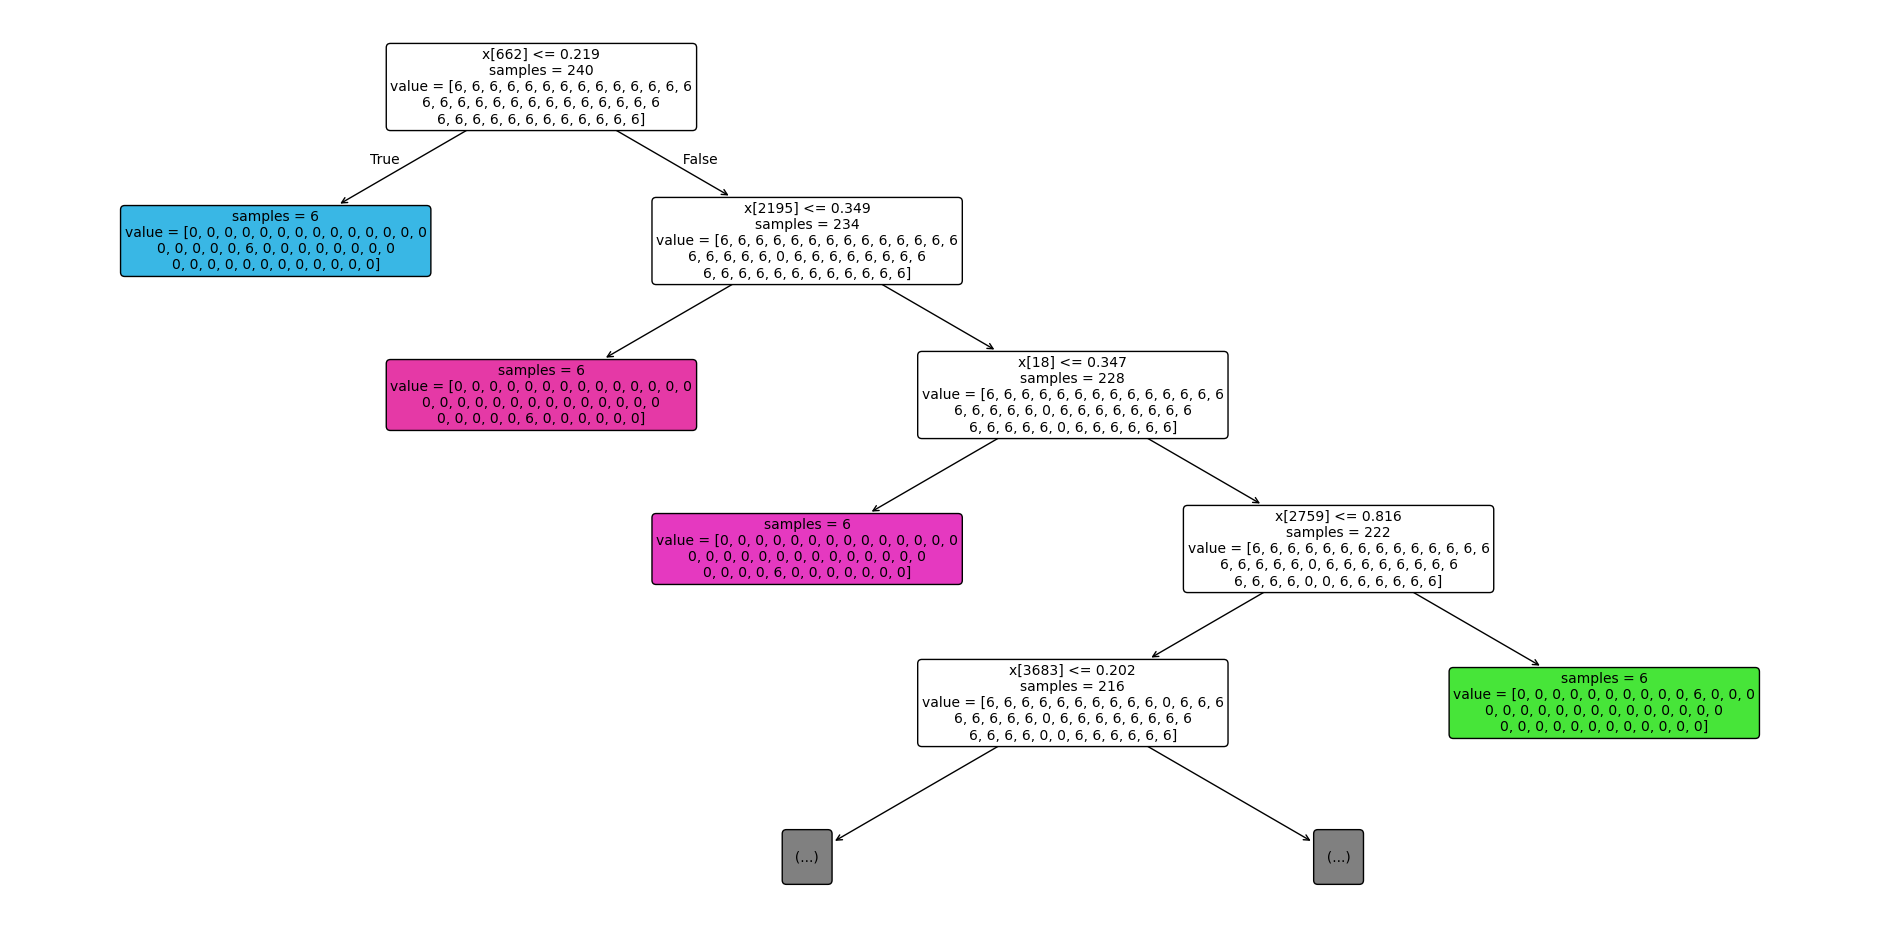

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    max_depth=4,
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=False
)

plt.show()

In [30]:
# Q1 (b)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import numpy as np

B_values = [1, 5, 10, 25, 50, 100, 200]


r1 = np.random.default_rng(26011)

models = []
distinct_samples = []

for i in range(200):

    idx = r1.choice(len(x_train), size=len(x_train), replace=True)

    x_boot = x_train[idx]
    y_boot = y_train[idx]

    model = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=26011 + i
    )

    model.fit(x_boot, y_boot)

    models.append(model)
    distinct_samples.append(len(np.unique(id)))

    if (i + 1) % 10 == 0:
        print("Trees trained:", i + 1)

Trees trained: 10
Trees trained: 20
Trees trained: 30
Trees trained: 40
Trees trained: 50
Trees trained: 60
Trees trained: 70
Trees trained: 80
Trees trained: 90
Trees trained: 100
Trees trained: 110
Trees trained: 120
Trees trained: 130
Trees trained: 140
Trees trained: 150
Trees trained: 160
Trees trained: 170
Trees trained: 180
Trees trained: 190
Trees trained: 200


In [31]:
def majority(predict):

    final_predict = []

    for i in range(predict.shape[1]):

        votes = np.bincount(predict[:, i], minlength=40)

        final_predict.append(np.argmax(votes))

    return np.array(final_predict)

In [32]:
results = []

for B in B_values:

    train_predict = []
    val_predict = []
    test_predict = []

    for i in range(B):

        train_predict.append(models[i].predict(x_train))
        val_predict.append(models[i].predict(x_val))
        test_predict.append(models[i].predict(x_test))

    train_predict = np.array(train_predict)
    val_predict = np.array(val_predict)
    test_predict = np.array(test_predict)

    train_final = majority(train_predict)
    val_final = majority(val_predict)
    test_final = majority(test_predict)

    train_accuracy = accuracy_score(y_train, train_final)
    val_accuracy = accuracy_score(y_val, val_final)
    test_accuracy = accuracy_score(y_test, test_final)

    avg_distinct = np.mean(distinct_samples[:B])

    results.append([
        B,
        train_accuracy,
        val_accuracy,
        test_accuracy,
        avg_distinct
    ])

bagging_results = pd.DataFrame(
    results,
    columns=[
        "B",
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy",
        "Average Distinct Samples"
    ]
)

bagging_results

,B,Training Accuracy,Validation Accuracy,Test Accuracy,Average Distinct Samples
0,1,0.758333,0.4000,0.3500,10.0
1,5,0.975000,0.6750,0.5375,10.0
2,10,1.000000,0.7625,0.6375,10.0
3,25,1.000000,0.8375,0.7250,10.0
4,50,1.000000,0.9000,0.7750,10.0
5,100,1.000000,0.9125,0.7875,10.0
6,200,1.000000,0.9000,0.8250,10.0


In [33]:
print("Best depth:", best_depth)
print("Best leaf:", best_leaf)
print("Trained trees:", len(models))
print("Distinct sample counts:", len(distinct_samples))

Best depth: None
Best leaf: 1
Trained trees: 200
Distinct sample counts: 200


In [34]:
n = len(x_train)

expected_distinct = n * (1 - (1 - 1/n)**n)

print("Expected distinct samples:", expected_distinct)
print("Observed average distinct samples:", np.mean(distinct_samples))

Expected distinct samples: 151.8931938460841
Observed average distinct samples: 10.0


In [35]:
#Q1(c)
boot_index = []

r1 = np.random.default_rng(26011)

for i in range(len(models)):
    idx = r1.choice(len(x_train), size=len(x_train), replace=True)
    boot_index.append(idx)


In [36]:
oobr = np.zeros(len(x_train))
oobc = np.zeros(len(x_train))

for i in range(len(models)):

    idx = boot_index[i]

    oob_id = np.setdiff1d(
        np.arange(len(x_train)),
        np.unique(idx)
    )

    if len(oob_id) > 0:
        pred = models[i].predict(x_train[oob_id])

        oobr[oob_id] += (pred == y_train[oob_id])
        oobc[oob_id] += 1

valid = oobc > 0

ooba = np.mean(
    oobr[valid] / oobc[valid]
)

print("OOB Accuracy:", ooba)
print("Training images with OOB predictions:", np.sum(valid))

OOB Accuracy: 0.32659236902052863
Training images with OOB predictions: 240


In [41]:
import numpy as np

B_values = [1, 5, 10, 25, 50, 100, 200]

wrong2 = []

for B in B_values:
    prediction = np.array([
        model.predict(x_test) for model in models[:B]
    ])

    wrong1 = []

    for i in range(B):
        for j in range(i + 1, B):
            wrong1.append(
                np.mean(prediction[i] != prediction[j])
            )

    wrong2.append(np.mean(wrong1) if wrong1 else 0)

for b, d in zip(B_values, wrong2):
    print("B =", b, "Pairwise disagreement =", d)

B = 1 Pairwise disagreement = 0
B = 5 Pairwise disagreement = 0.8225000000000001
B = 10 Pairwise disagreement = 0.8094444444444444
B = 25 Pairwise disagreement = 0.7957916666666667
B = 50 Pairwise disagreement = 0.7952653061224491
B = 100 Pairwise disagreement = 0.7938737373737375
B = 200 Pairwise disagreement = 0.7904786432160805


In [42]:
marginout = []

for B in B_values:

    prediction = []

    for i in range(B):
        prediction.append(models[i].predict(x_val))

    prediction = np.array(prediction)

    margins = []

    for i in range(len(x_val)):

        votes = np.bincount(prediction[:, i], minlength=40)
        sorted_votes = np.sort(votes)

        margin = (sorted_votes[-1] - sorted_votes[-2]) / B

        margins.append(margin)

    mean_margin = np.mean(margins)

    marginout.append([B, mean_margin])

marginout = pd.DataFrame(
    marginout,
    columns=["B", "Mean Vote Margin"]
)

marginout

,B,Mean Vote Margin
0,1,1.000000
1,5,0.242500
2,10,0.283750
3,25,0.286000
4,50,0.297250
5,100,0.292125
6,200,0.302000


In [46]:
wrong = pd.DataFrame({
    "B": B_values,
    "Pairwise Disagreement": wrong2
})

marginout = pd.DataFrame({
    "B": B_values,
    "Mean Vote Margin": [1.000000, 0.242500, 0.283750, 0.286000,
                         0.297250, 0.292125, 0.302000]
})

output = wrong.merge(marginout, on="B")

print(output)

     B  Pairwise Disagreement  Mean Vote Margin
0    1               0.000000          1.000000
1    5               0.822500          0.242500
2   10               0.809444          0.283750
3   25               0.795792          0.286000
4   50               0.795265          0.297250
5  100               0.793874          0.292125
6  200               0.790479          0.302000


In [47]:
# Q1 (d)

x_masked = x_test.reshape(-1, 64, 64).copy()

x_masked[:, 24:40, 24:40] = 0

x_masked = x_masked.reshape(-1, 4096)

In [48]:
treec = best_model.predict(x_test)
treem = best_model.predict(x_masked)

print("Decision Tree Clean Accuracy:",
      accuracy_score(y_test, treec))

print("Decision Tree Masked Accuracy:",
      accuracy_score(y_test, treem))

Decision Tree Clean Accuracy: 0.525
Decision Tree Masked Accuracy: 0.275


In [49]:
baggc = []
baggm = []

for i in range(200):
    baggc.append(models[i].predict(x_test))
    baggm.append(models[i].predict(x_masked))

baggc= majority(np.array(baggc))
baggm= majority(np.array(baggm))

print("Bagging Clean Accuracy:",
      accuracy_score(y_test, baggc))

print("Bagging Masked Accuracy:",
      accuracy_score(y_test, baggm))

Bagging Clean Accuracy: 0.825
Bagging Masked Accuracy: 0.6875


In [50]:
outputd = pd.DataFrame({
    "Model": ["Decision Tree", "Decision Tree",
              "Bagging", "Bagging"],
    "Test Images": ["Clean", "Masked", "Clean", "Masked"],
    "Accuracy": [
        accuracy_score(y_test, treec),
        accuracy_score(y_test, treem),
        accuracy_score(y_test, baggc),
        accuracy_score(y_test, baggm)
    ]
})

print(outputd.to_string(index=False))

        Model Test Images  Accuracy
Decision Tree       Clean    0.5250
Decision Tree      Masked    0.2750
      Bagging       Clean    0.8250
      Bagging      Masked    0.6875


In [51]:
treec_conf = np.mean(
    np.max(best_model.predict_proba(x_test), axis=1)
)

treem_conf = np.mean(
    np.max(best_model.predict_proba(x_masked), axis=1)
)

# Bagging confidence

def votec(predictions):
    conf = []

    for i in range(predictions.shape[1]):
        votes = np.bincount(predictions[:, i], minlength=40)
        conf.append(np.max(votes) / predictions.shape[0])

    return np.mean(conf)

baggc_predict = np.array([
    models[i].predict(x_test) for i in range(200)
])

baggm_predict = np.array([
    models[i].predict(x_masked) for i in range(200)
])

print("Tree clean confidence:", treec_conf)
print("Tree masked confidence:", treem_conf)

print("Bagging clean confidence:",
      votec(baggc_predict))

print("Bagging masked confidence:",
      votec(baggm_predict))

Tree clean confidence: 1.0
Tree masked confidence: 1.0
Bagging clean confidence: 0.3868125
Bagging masked confidence: 0.27149999999999996


In [52]:
twbc = np.where(
    (treec != y_test) & (baggc == y_test)
)[0]

bw= np.where(
    (treec != y_test) & (baggc != y_test)
)[0]

print("Tree wrong, bagging correct:",
      len(twbc))

print("Both models wrong:", len(bw))

Tree wrong, bagging correct: 25
Both models wrong: 13


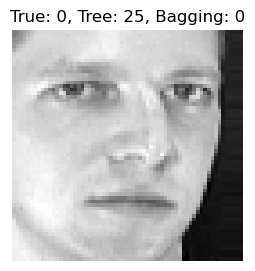

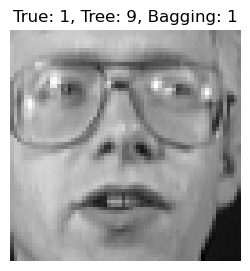

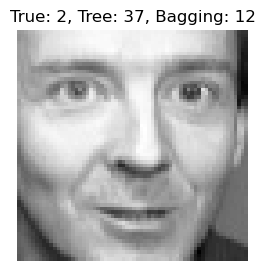

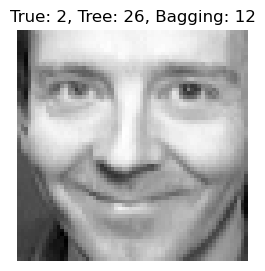

In [53]:
import matplotlib.pyplot as plt

examples = list(twbc[:2]) + list(bw[:2])

for i in examples:
    plt.figure(figsize=(3, 3))
    plt.imshow(x_test[i].reshape(64, 64), cmap="gray")
    plt.title(
        f"True: {y_test[i]}, Tree: {treec[i]}, "
        f"Bagging: {baggc[i]}"
    )
    plt.axis("off")
    plt.show()

In [54]:
#Q2(a)
import numpy as np
from sklearn.tree import DecisionTreeClassifier
X_small = np.array([
    [1, 1],
    [1, 2],
    [2, 1],
    [2, 2],
    [4, 4],
    [4, 5],
    [5, 4],
    [5, 5],
    [8, 8]
])

y_small = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

n = len(y_small)
weights = np.ones(n) / n

print("Number of samples:", n)
print("Classes:", np.unique(y_small))
print("Initial sample weights:", weights)
print("Sum of weights:", weights.sum())

Number of samples: 9
Classes: [0 1 2]
Initial sample weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Sum of weights: 1.0


In [56]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=1, random_state=26011)

model.fit(X_small, y_small, sample_weight=weights)

predictions = model.predict(X_small)

print("Actual classes:", y_small)
print("Predicted classes:", predictions)

Actual classes: [0 0 0 1 1 1 2 2 2]
Predicted classes: [0 0 0 0 0 0 2 2 2]


In [57]:
wrong4 = (predictions != y_small)

error = np.sum(weights * wrong4)

print("Incorrect predictions:", wrong4)
print("Weighted error:", error)

Incorrect predictions: [False False False  True  True  True False False False]
Weighted error: 0.3333333333333333


In [58]:
K = len(np.unique(y_small))

a = np.log((1 - error) / error) + np.log(K - 1)

print("Number of classes:", K)
print("Weighted error:", error)
print("Learner weight:", a)

Number of classes: 3
Weighted error: 0.3333333333333333
Learner weight: 1.3862943611198908


In [59]:
new_w = weights.copy()

for i in range(len(y_small)):
    if predictions[i] != y_small[i]:
        new_w[i] = weights[i] * np.exp(a)

new_w = new_w / np.sum(new_w)

print("Old weights:")
print(weights)

print("\nUpdated normalized weights:")
print(new_w)

print("\nSum of updated weights:", np.sum(new_w))

Old weights:
[0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]

Updated normalized weights:
[0.05555556 0.05555556 0.05555556 0.22222222 0.22222222 0.22222222
 0.05555556 0.05555556 0.05555556]

Sum of updated weights: 1.0


In [69]:
#Q2(b)



In [19]:

import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

def train_samme(X, y, depth, T):
    classes = np.unique(y)
    n = len(y)
    K = len(classes)
    w = np.ones(n) / n
    models = []
    alphas = []
    weight_history = [w.copy()]

    for t in range(T):
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=26011 + t
        )
        model.fit(X, y, sample_weight=w)
        pred = model.predict(X)
        err = np.sum(w * (pred != y))

        if err >= 1 - 1 / K:
            break

        err = max(err, 1e-12)
        alpha = np.log((1 - err) / err) + np.log(K - 1)

        w *= np.exp(alpha * (pred != y))
        w /= w.sum()

        models.append(model)
        alphas.append(alpha)
        weight_history.append(w.copy())

        if err == 0:
            break

    return {
        "models": models,
        "alphas": np.array(alphas),
        "weight_history": np.array(weight_history),
        "classes": classes
    }

def predict_samme(models, alphas, X, classes):
    scores = np.zeros((len(X), len(classes)))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X)
        for j, c in enumerate(classes):
            scores[:, j] += alpha * (pred == c)

    return classes[np.argmax(scores, axis=1)]

depths = [1, 2, 3, 4]
rounds = [10, 25, 50, 100]
results = []

for depth in depths:
    for T in rounds:
        r = train_samme(x_train, y_train, depth, T)
        val_pred = predict_samme(
            r["models"], r["alphas"], x_val, r["classes"]
        )

        results.append({
            "depth": depth,
            "requested_rounds": T,
            "validation_accuracy": accuracy_score(y_val, val_pred),
            "result": r
        })

best = max(results, key=lambda row: row["validation_accuracy"])
r = best["result"]

models = r["models"]
alphas = r["alphas"]
weight_history = r["weight_history"]
classes = r["classes"]

train_pred = predict_samme(models, alphas, x_train, classes)
test_pred = predict_samme(models, alphas, x_test, classes)

print("Best depth:", best["depth"])
print("Requested rounds:", best["requested_rounds"])
print("Actual rounds:", len(models))
print("Training accuracy:", accuracy_score(y_train, train_pred))
print("Training error:", 1 - accuracy_score(y_train, train_pred))
print("Validation accuracy:", best["validation_accuracy"])
print("Test accuracy:", accuracy_score(y_test, test_pred))

print("\nLearner weights:")
for t, alpha in enumerate(alphas, start=1):
    print(f"Round {t}: {alpha:.6f}")

mistake_counts = np.zeros(len(y_train))

for model in models:
    mistake_counts += model.predict(x_train) != y_train

hardest = np.argsort(mistake_counts)[-10:][::-1]

print("\n10 hardest training images (indices):")
print(hardest)

print("\nMaximum sample weight in each round:")
print(np.max(weight_history, axis=1))

print("\nCombined weight of the 10 hardest images in each round:")
print(weight_history[:, hardest].sum(axis=1))


Best depth: 4
Requested rounds: 100
Actual rounds: 100
Training accuracy: 0.9708333333333333
Training error: 0.029166666666666674
Validation accuracy: 0.475
Test accuracy: 0.425

Learner weights:
Round 1: 1.717651
Round 2: 1.842326
Round 3: 1.994980
Round 4: 2.407141
Round 5: 2.531992
Round 6: 2.865220
Round 7: 3.698654
Round 8: 4.161675
Round 9: 2.733784
Round 10: 2.708225
Round 11: 2.817927
Round 12: 2.949460
Round 13: 3.140770
Round 14: 2.925297
Round 15: 3.567497
Round 16: 3.180167
Round 17: 3.011882
Round 18: 3.098983
Round 19: 3.051622
Round 20: 2.864743
Round 21: 3.016122
Round 22: 2.967109
Round 23: 3.175411
Round 24: 2.804298
Round 25: 3.079234
Round 26: 2.948958
Round 27: 2.929271
Round 28: 3.064166
Round 29: 3.284225
Round 30: 3.071851
Round 31: 2.894504
Round 32: 2.813205
Round 33: 2.903246
Round 34: 2.901655
Round 35: 2.833857
Round 36: 2.947780
Round 37: 3.005722
Round 38: 3.138276
Round 39: 2.778128
Round 40: 3.001404
Round 41: 2.968379
Round 42: 3.079024
Round 43: 2.975

In [60]:
#Q2(c)

x_ti = x_test.reshape(-1, 64, 64).copy()

x_tmi = x_ti.copy()
x_tmi[:, 24:40, 24:40] = 0


x_tm = x_tmi.reshape(-1, 4096)

print("Clean test shape:", x_test.shape)
print("Masked test shape:", x_tm.shape)

Clean test shape: (80, 4096)
Masked test shape: (80, 4096)


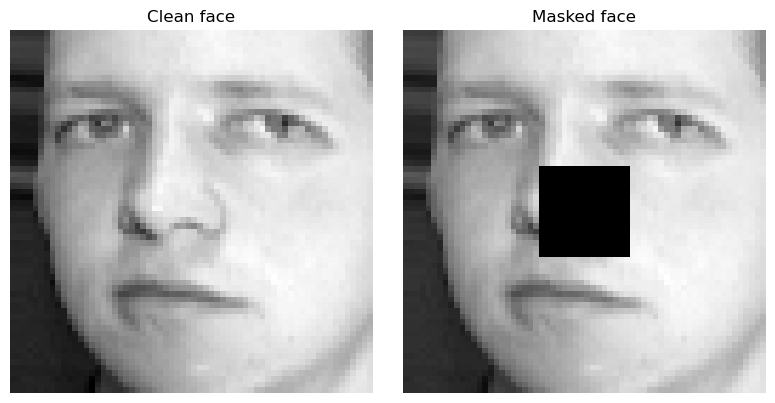

In [61]:
import matplotlib.pyplot as plt

i = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_test[i].reshape(64, 64), cmap="gray")
plt.title("Clean face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(x_tm[i].reshape(64, 64), cmap="gray")
plt.title("Masked face")
plt.axis("off")

plt.tight_layout()
plt.show()

In [63]:
print(type(results))
print(type(results[0]))
print(results[0])

<class 'list'>
<class 'list'>
[1, 0.7583333333333333, 0.4, 0.35, 10.0]


In [65]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score

classes = np.unique(y_train)

def boost_fit(X, y, depth, T=100, seed=26011):
    n = len(y)
    K = len(classes)
    w = np.ones(n) / n

    models = []
    alphas = []

    for t in range(T):
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        model.fit(X, y, sample_weight=w)
        pred = model.predict(X)

        error = np.sum(w * (pred != y))

        if error >= 1 - 1/K:
            break

        error = max(error, 1e-10)
        alpha = np.log((1 - error) / error) + np.log(K - 1)

        w *= np.exp(alpha * (pred != y))
        w /= np.sum(w)

        models.append(model)
        alphas.append(alpha)

        if error == 0:
            break

    return models, alphas


def predict_samme(models, alphas, X, classes):
    scores = np.zeros((len(X), len(classes)))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X)

        for j, c in enumerate(classes):
            scores[:, j] += alpha * (pred == c)

    return classes[np.argmax(scores, axis=1)]


samme_models, samme_alphas = boost_fit(
    x_train, y_train,
    depth=4,
    T=100,
    seed=26011
)

tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=26011
)
tree_model.fit(x_train, y_train)

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=4),
    n_estimators=100,
    random_state=26011
)
bagging_model.fit(x_train, y_train)

samme_clean = predict_samme(
    samme_models, samme_alphas, x_test, classes
)
samme_masked = predict_samme(
    samme_models, samme_alphas, x_tm, classes
)

tree_clean = tree_model.predict(x_test)
tree_masked = tree_model.predict(x_tm)

bag_clean = bagging_model.predict(x_test)
bag_masked = bagging_model.predict(x_tm)

print("SAMME clean accuracy:", accuracy_score(y_test, samme_clean))
print("SAMME masked accuracy:", accuracy_score(y_test, samme_masked))

print("Decision Tree clean accuracy:", accuracy_score(y_test, tree_clean))
print("Decision Tree masked accuracy:", accuracy_score(y_test, tree_masked))

print("Bagging clean accuracy:", accuracy_score(y_test, bag_clean))
print("Bagging masked accuracy:", accuracy_score(y_test, bag_masked))

SAMME clean accuracy: 0.425
SAMME masked accuracy: 0.4
Decision Tree clean accuracy: 0.1125
Decision Tree masked accuracy: 0.1125
Bagging clean accuracy: 0.55
Bagging masked accuracy: 0.3875


In [66]:
#Q2(d)
a = np.where(samme_clean != samme_masked)[0]

print("Changed image indices:", a)

b = []
c = []

for i in a:
    if samme_clean[i] == y_test[i] and samme_masked[i] != y_test[i]:
        b.append(i)  # Correct -> Wrong

    elif samme_clean[i] != y_test[i] and samme_masked[i] == y_test[i]:
        c.append(i)  # Wrong -> Correct

print("Correct to wrong:", b)
print("Wrong to correct:", c)

Changed image indices: [ 0 14 15 16 19 24 27 40 49 57 68 69 70 71]
Correct to wrong: [14, 16, 24, 49]
Wrong to correct: [27, 40]


Image index: 0
Actual identity: 0
Clean prediction: 3
Masked prediction: 20


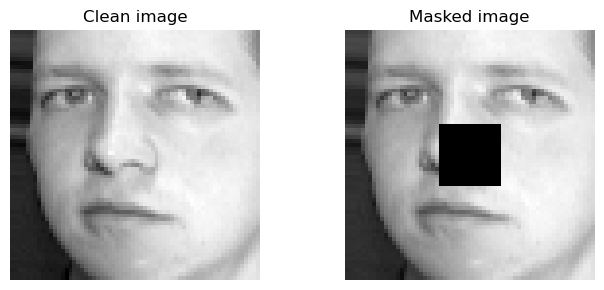

Image index: 14
Actual identity: 7
Clean prediction: 7
Masked prediction: 3


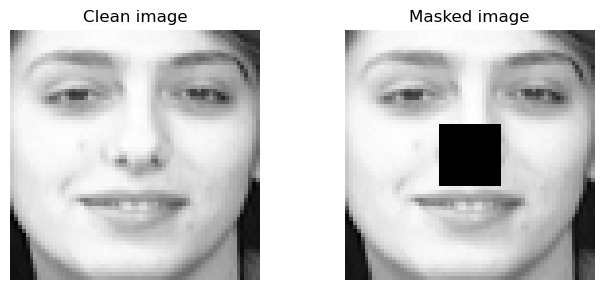

Image index: 15
Actual identity: 7
Clean prediction: 3
Masked prediction: 20


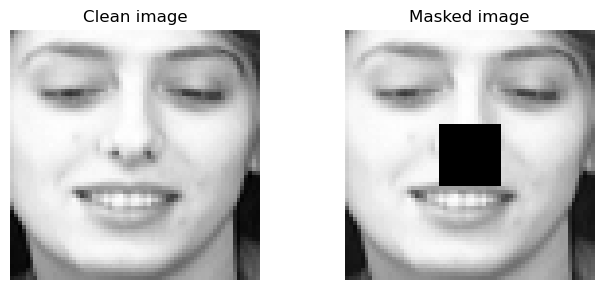

In [67]:
for i in a[:3]:
    print("Image index:", i)
    print("Actual identity:", y_test[i])
    print("Clean prediction:", samme_clean[i])
    print("Masked prediction:", samme_masked[i])

    plt.figure(figsize=(7, 3))

    plt.subplot(1, 2, 1)
    plt.imshow(x_test[i].reshape(64, 64), cmap="gray")
    plt.title("Clean image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(x_tm[i].reshape(64, 64), cmap="gray")
    plt.title("Masked image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [68]:
for i in a:
    print(
        "Index:", i,
        "| Actual:", y_test[i],
        "| Clean:", samme_clean[i],
        "| Masked:", samme_masked[i]
    )

Index: 0 | Actual: 0 | Clean: 3 | Masked: 20
Index: 14 | Actual: 7 | Clean: 7 | Masked: 3
Index: 15 | Actual: 7 | Clean: 3 | Masked: 20
Index: 16 | Actual: 8 | Clean: 8 | Masked: 3
Index: 19 | Actual: 9 | Clean: 3 | Masked: 12
Index: 24 | Actual: 12 | Clean: 12 | Masked: 3
Index: 27 | Actual: 13 | Clean: 2 | Masked: 13
Index: 40 | Actual: 20 | Clean: 12 | Masked: 20
Index: 49 | Actual: 24 | Clean: 24 | Masked: 3
Index: 57 | Actual: 28 | Clean: 3 | Masked: 12
Index: 68 | Actual: 34 | Clean: 3 | Masked: 12
Index: 69 | Actual: 34 | Clean: 3 | Masked: 12
Index: 70 | Actual: 35 | Clean: 23 | Masked: 20
Index: 71 | Actual: 35 | Clean: 23 | Masked: 12


In [72]:
#Q3(a)
import numpy as np
from sklearn.tree import DecisionTreeClassifier

classes = np.unique(y_train)

def tree_vector(model, X):
    prob = model.predict_proba(X)
    output = np.zeros((len(X), len(classes)))

    for i, c in enumerate(model.classes_):
        j = np.where(classes == c)[0][0]
        output[:, j] = prob[:, i]

    return output


def bag_fit(X, y, depth, B=20, leaf=1, seed=26011):
    rng = np.random.default_rng(seed)
    models = []

    for i in range(B):
        ix = rng.choice(len(y), size=len(y), replace=True)

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=seed + i
        )

        model.fit(X[ix], y[ix])
        models.append(model)

    return models


def bag_vector(models, X):
    predictions = np.array([
        tree_vector(model, X) for model in models
    ])

    return predictions.mean(axis=0)


def boost_fit(X, y, depth, T=20, seed=26011):
    classes = np.unique(y)
    K = len(classes)
    w = np.ones(len(y)) / len(y)

    models = []
    alphas = []

    for t in range(T):
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        model.fit(X, y, sample_weight=w)
        pred = model.predict(X)

        error = np.sum(w * (pred != y))

        if error >= 1 - 1/K:
            break

        error = max(error, 1e-10)
        alpha = np.log((1 - error) / error) + np.log(K - 1)

        w *= np.exp(alpha * (pred != y))
        w /= np.sum(w)

        models.append(model)
        alphas.append(alpha)

        if error == 0:
            break

    return models, alphas


def boost_vector(models, alphas, X):
    scores = np.zeros((len(X), len(classes)))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X)

        for j, c in enumerate(classes):
            scores[:, j] += alpha * (pred == c)

    return scores / np.sum(alphas)

In [73]:
from sklearn.metrics import accuracy_score

R = 5
B_final = 20
T_final = 20

r3 = np.random.default_rng(26011)
classes = np.unique(y_train)
a1 = []

for i in range(R):
    ix = []
    for c in classes:
        ids = np.where(y_train == c)[0]
        ix.extend(r3.choice(ids, size=len(ids), replace=True))
    ix = np.array(ix)
    a1.append((x_train[ix], y_train[ix]))

a2, a3, a4 = [], [], []
a5, a6, a7 = [], [], []

for i, (x_r, y_r) in enumerate(a1):
    m1 = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=26011 + i
    )
    m1.fit(x_r, y_r)
    p1 = tree_vector(m1, x_test)
    a2.append(p1)
    a5.append(accuracy_score(y_test, classes[np.argmax(p1, axis=1)]))

    m2 = bag_fit(
        x_r, y_r, best_depth,
        B=B_final, leaf=best_leaf,
        seed=27000 + i * 1000
    )
    p2 = bag_vector(m2, x_test)
    a3.append(p2)
    a6.append(accuracy_score(y_test, classes[np.argmax(p2, axis=1)]))

    m3, al3 = boost_fit(
        x_r, y_r, best["depth"],
        T=T_final, seed=28000 + i * 1000
    )
    p3 = boost_vector(m3, al3, x_test)
    a4.append(p3)
    a7.append(accuracy_score(y_test, classes[np.argmax(p3, axis=1)]))

a2 = np.asarray(a2)
a3 = np.asarray(a3)
a4 = np.asarray(a4)

y_one = (y_test[:, None] == classes[None, :]).astype(float)

for name, p, acc in [
    ("Single Tree", a2, a5),
    ("Bagging", a3, a6),
    ("SAMME Boosting", a4, a7)
]:
    mean_p = p.mean(axis=0)
    bias2 = np.mean(np.sum((mean_p - y_one) ** 2, axis=1))
    variance = np.mean(np.sum((p - mean_p[None, :, :]) ** 2, axis=2))

    print("\n", name)
    print("Bias squared:", bias2)
    print("Variance:", variance)
    print("Mean test accuracy:", np.mean(acc))
    print("Test accuracy standard deviation:", np.std(acc))


 Single Tree
Bias squared: 0.5330000000000001
Variance: 0.557
Mean test accuracy: 0.45499999999999996
Test accuracy standard deviation: 0.02318404623873926

 Bagging
Bias squared: 0.5407474999999999
Variance: 0.0457525
Mean test accuracy: 0.67
Test accuracy standard deviation: 0.02573907535246752

 SAMME Boosting
Bias squared: 0.9081715801791255
Variance: 0.02528547181341819
Mean test accuracy: 0.16
Test accuracy standard deviation: 0.06819090848492927


In [75]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

R = 3
B = 20

depths = [2, best_depth, 32]
depths = list(dict.fromkeys(depths))

r3 = np.random.default_rng(26012)
classes = np.unique(y_train)
a1 = []

for i in range(R):
    ix = []
    for c in classes:
        ids = np.where(y_train == c)[0]
        ix.extend(r3.choice(ids, size=len(ids), replace=True))
    ix = np.array(ix)
    a1.append((x_train[ix], y_train[ix]))

y_one = (y_test[:, None] == classes[None, :]).astype(float)
results = []

for depth in depths:
    single_preds = []
    bag_preds = []
    single_acc = []
    bag_acc = []

    for i, (x_r, y_r) in enumerate(a1):
        m1 = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=31000 + i
        )
        m1.fit(x_r, y_r)

        p1 = tree_vector(m1, x_test)
        single_preds.append(p1)
        single_acc.append(
            accuracy_score(y_test, classes[np.argmax(p1, axis=1)])
        )

        m2 = bag_fit(
            x_r, y_r, depth,
            B=B, leaf=best_leaf,
            seed=32000 + i * 1000
        )
        p2 = bag_vector(m2, x_test)
        bag_preds.append(p2)
        bag_acc.append(
            accuracy_score(y_test, classes[np.argmax(p2, axis=1)])
        )

    single_preds = np.asarray(single_preds)
    bag_preds = np.asarray(bag_preds)

    mean_single = single_preds.mean(axis=0)
    mean_bag = bag_preds.mean(axis=0)

    bias_single = np.mean(
        np.sum((mean_single - y_one) ** 2, axis=1)
    )
    var_single = np.mean(
        np.sum((single_preds - mean_single[None, :, :]) ** 2, axis=2)
    )

    bias_bag = np.mean(
        np.sum((mean_bag - y_one) ** 2, axis=1)
    )
    var_bag = np.mean(
        np.sum((bag_preds - mean_bag[None, :, :]) ** 2, axis=2)
    )

    results.append({
        "Depth": str(depth),
        "Single Bias²": bias_single,
        "Single Variance": var_single,
        "Single Accuracy": np.mean(single_acc),
        "Bagging Bias²": bias_bag,
        "Bagging Variance": var_bag,
        "Bagging Accuracy": np.mean(bag_acc),
        "Variance Removed": var_single - var_bag
    })

import pandas as pd
df_q3b = pd.DataFrame(results)
print(df_q3b.round(4).to_string(index=False))

Depth  Single Bias²  Single Variance  Single Accuracy  Bagging Bias²  Bagging Variance  Bagging Accuracy  Variance Removed
    2        0.9233           0.0359           0.0667         0.9301            0.0018            0.2917            0.0341
 None        0.6500           0.4583           0.4458         0.5550            0.0376            0.6250            0.4207
   32        0.6564           0.4162           0.4167         0.5625            0.0344            0.6417            0.3818


In [78]:
# Q3(c)

import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

classes = np.unique(y_train)
n_classes = len(classes)

a6 = []

for depth in depth_values:
    improvements = []
    occupancies = []
    disagreements = []

    for i, (x_r, y_r) in enumerate(a1):
        m1 = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_leaf,
            random_state=41000 + i
        )

        m1.fit(x_r, y_r)
        acc1 = accuracy_score(y_test, m1.predict(x_test))

        leaf_ids = m1.apply(x_r)
        counts = np.unique(leaf_ids, return_counts=True)[1]
        occupancies.append(np.mean(counts))

        ms = bag_fit(
            x_r, y_r, depth,
            B=20,
            leaf=best_leaf,
            seed=42000 + i * 1000
        )

        pred = np.array([m.predict(x_test) for m in ms])

        bag_pred = np.array([
            classes[
                np.bincount(
                    np.searchsorted(classes, pred[:, j]),
                    minlength=n_classes
                ).argmax()
            ]
            for j in range(len(y_test))
        ])

        improvements.append(
            accuracy_score(y_test, bag_pred) - acc1
        )

        d = []

        for j in range(len(ms)):
            for k in range(j + 1, len(ms)):
                d.append(np.mean(pred[j] != pred[k]))

        disagreements.append(np.mean(d))

    a6.append({
        "depth": depth,
        "accuracy_improvement": np.mean(improvements),
        "mean_leaf_occupancy": np.mean(occupancies),
        "pairwise_disagreement": np.mean(disagreements)
    })

for row in a6:
    print("\nDepth:", row["depth"])
    print("Bagging accuracy improvement:", row["accuracy_improvement"])
    print("Mean leaf occupancy:", row["mean_leaf_occupancy"])
    print("Pairwise disagreement:", row["pairwise_disagreement"])

best_improvement = max(
    a6,
    key=lambda row: row["accuracy_improvement"]
)

print(
    "\nDepth with largest bagging improvement:",
    best_improvement["depth"]
)


Depth: 2
Bagging accuracy improvement: 0.0
Mean leaf occupancy: 80.0
Pairwise disagreement: 0.9512719298245614

Depth: 4
Bagging accuracy improvement: 0.033333333333333326
Mean leaf occupancy: 48.0
Pairwise disagreement: 0.9434429824561402

Depth: 8
Bagging accuracy improvement: 0.15416666666666667
Mean leaf occupancy: 25.777777777777782
Pairwise disagreement: 0.9324342105263158

Depth: 16
Bagging accuracy improvement: 0.20833333333333334
Mean leaf occupancy: 13.594771241830067
Pairwise disagreement: 0.8923684210526316

Depth: None
Bagging accuracy improvement: 0.1958333333333333
Mean leaf occupancy: 6.0
Pairwise disagreement: 0.8163157894736842

Depth with largest bagging improvement: 16


In [80]:
#Q3 (D)
def measure(p, y):
    mean_p = p.mean(axis=0)

    y_one = (y[:, None] == classes[None, :]).astype(float)

    bias2 = np.mean(
        np.sum((mean_p - y_one) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum((p - mean_p[None, :, :]) ** 2, axis=2)
    )

    acc = np.mean([
        accuracy_score(y, classes[np.argmax(pred, axis=1)])
        for pred in p
    ])

    sd = np.std([
        accuracy_score(y, classes[np.argmax(pred, axis=1)])
        for pred in p
    ])

    return bias2, variance, acc, sd

In [82]:
# Q3(d)

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

B_final = 20
T_final = 20

x_test_masked = x_test.reshape(-1, 64, 64).copy()
x_test_masked[:, 24:40, 24:40] = 0
x_test_masked = x_test_masked.reshape(len(x_test), -1)

classes = np.unique(y_train)

a7 = {
    "Single Tree": {"clean": [], "masked": []},
    "Bagging": {"clean": [], "masked": []},
    "SAMME Boosting": {"clean": [], "masked": []}
}

for i, (x_r, y_r) in enumerate(a1):
    m1 = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_leaf,
        random_state=51000 + i
    )
    m1.fit(x_r, y_r)

    a7["Single Tree"]["clean"].append(tree_vector(m1, x_test))
    a7["Single Tree"]["masked"].append(tree_vector(m1, x_test_masked))

    m2 = bag_fit(
        x_r, y_r, best_depth,
        B=B_final,
        leaf=best_leaf,
        seed=52000 + i * 1000
    )

    a7["Bagging"]["clean"].append(bag_vector(m2, x_test))
    a7["Bagging"]["masked"].append(bag_vector(m2, x_test_masked))

    m3, al3 = boost_fit(
        x_r, y_r, best["depth"],
        T=T_final,
        seed=53000 + i * 1000
    )

    a7["SAMME Boosting"]["clean"].append(
        boost_vector(m3, al3, x_test)
    )

    a7["SAMME Boosting"]["masked"].append(
        boost_vector(m3, al3, x_test_masked)
    )



In [83]:
a8 = []

for name, values in a7.items():
    pc = np.array(values["clean"])
    pm = np.array(values["masked"])

    b2, v, ac, sd = measure(pc, y_test)

    masked_acc = np.mean([
        accuracy_score(
            y_test,
            classes[np.argmax(p, axis=1)]
        )
        for p in pm
    ])

    a8.append({
        "Model": name,
        "Clean Test Accuracy": ac,
        "Masked Test Accuracy": masked_acc,
        "Bias Squared": b2,
        "Variance": v,
        "Accuracy Std": sd
    })

a8 = pd.DataFrame(a8)

print(a8.round(4).to_string(index=False))

         Model  Clean Test Accuracy  Masked Test Accuracy  Bias Squared  Variance  Accuracy Std
   Single Tree               0.4500                0.2958        0.6667    0.4333        0.0204
       Bagging               0.6458                0.4125        0.5479    0.0389        0.0482
SAMME Boosting               0.1208                0.1667        0.9192    0.0212        0.0236
